In [7]:
import joblib
import numpy as np
import matplotlib.pyplot as plt

In [9]:
def plot_distributions(all_H1, all_H0):
    
    x = np.linspace(0, 1, 1000).reshape(-1, 1)
    
    for i, (kde_H1, kde_H0) in enumerate(zip(all_H1, all_H0)):
        log_dens_H1 = kde_H1.score_samples(x)
        log_dens_H0 = kde_H0.score_samples(x)
    
        dens_H1 = np.exp(log_dens_H1)
        dens_H0 = np.exp(log_dens_H0)
    
        plt.figure()
        plt.plot(x, dens_H0, label="H0 (bonafide)")
        plt.plot(x, dens_H1, label="H1 (spoof)")
        plt.title(f"Expert {i}")
        plt.xlabel("Probability")
        plt.ylabel("Density")
        plt.legend()
        plt.grid()
        plt.show()

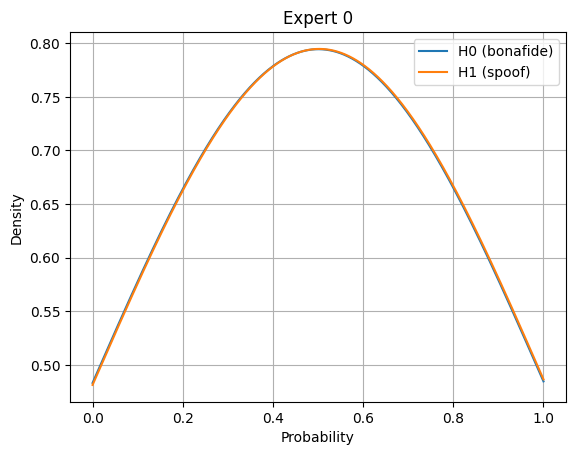

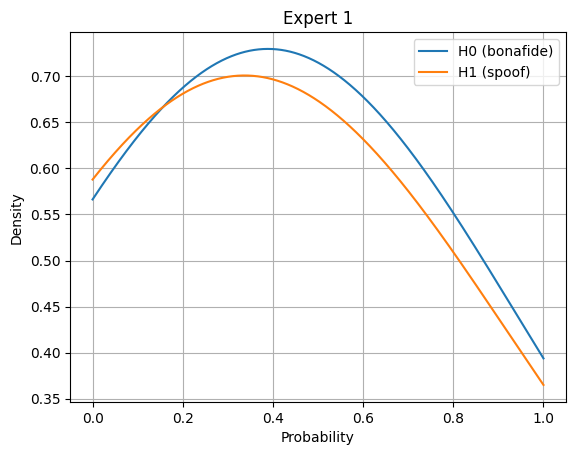

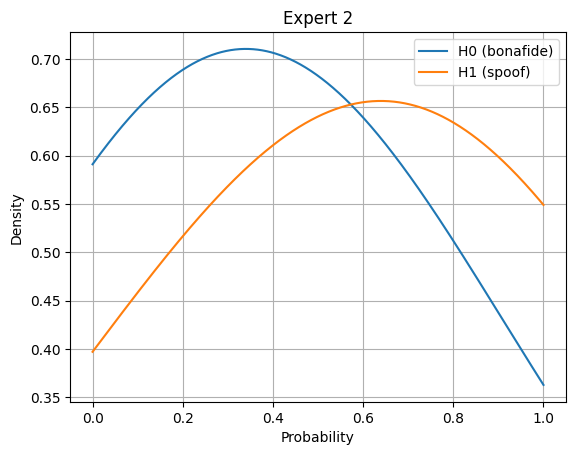

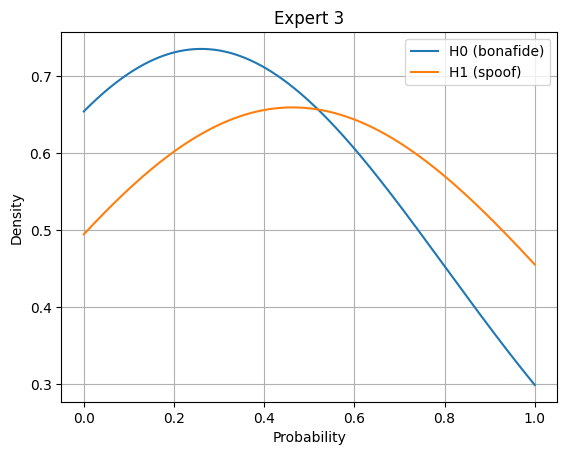

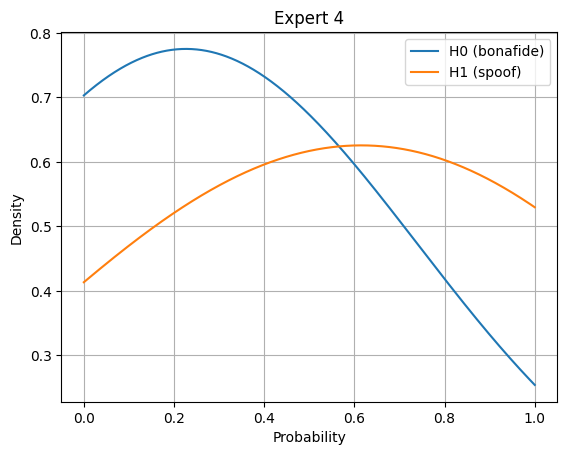

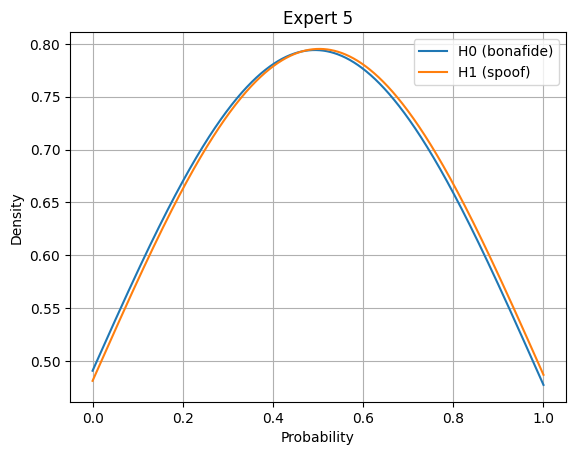

In [10]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/temp/trials4/"
all_H1 = joblib.load(f"{rootpath}/all_H1.pkl")
all_H0 = joblib.load(f"{rootpath}/all_H0.pkl")
plot_distributions(all_H1, all_H0)

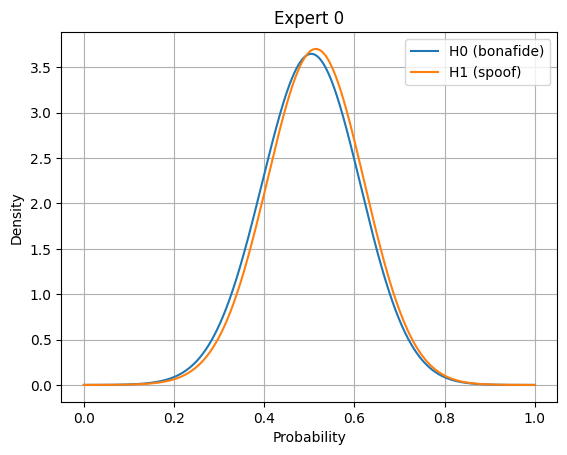

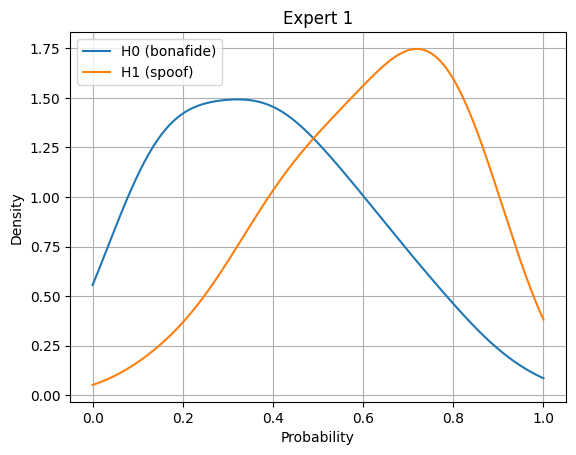

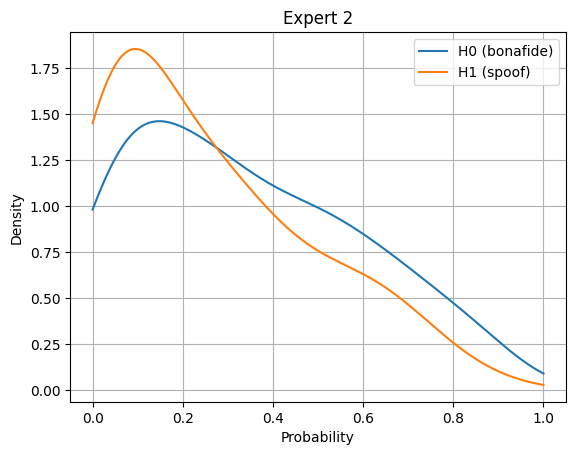

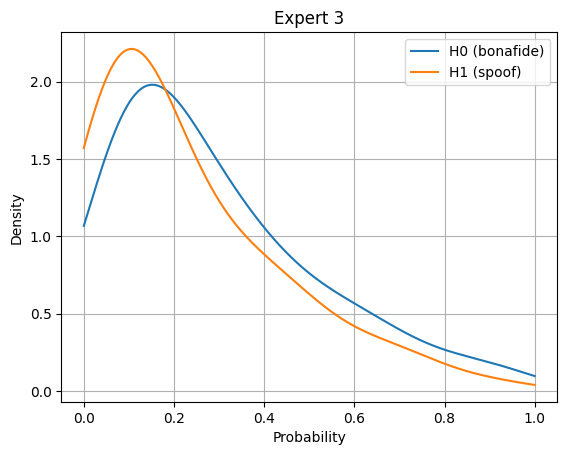

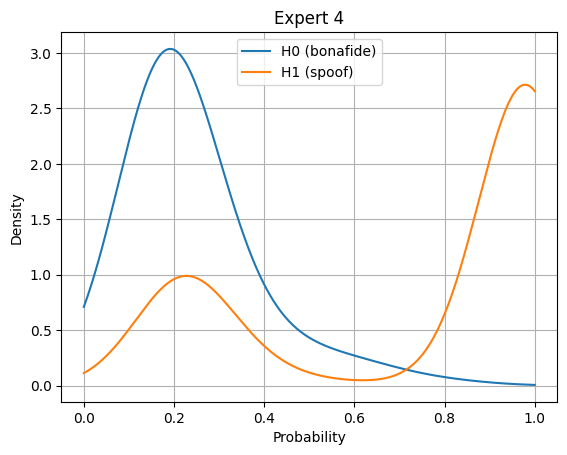

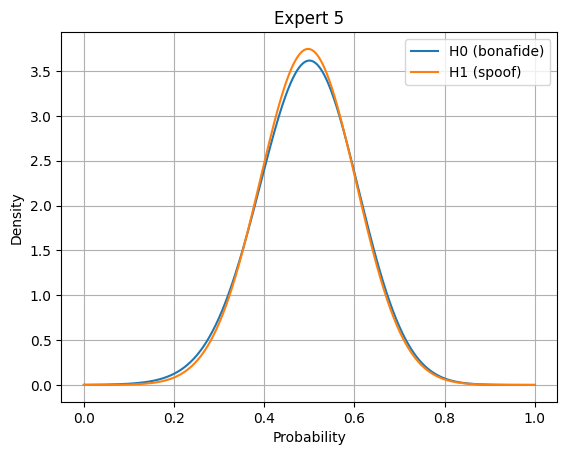

In [11]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/temp/trials5/"
all_H1 = joblib.load(f"{rootpath}/all_H1.pkl")
all_H0 = joblib.load(f"{rootpath}/all_H0.pkl")
plot_distributions(all_H1, all_H0)

In [38]:
from scipy.stats import norm

def plot_distributions(all_me, all_md, all_v):
    
    for i, (m_e, m_d, v) in enumerate(zip(all_me, all_md, all_v)):
        
        # --- RAW SPACE ---
        sigma_raw = np.sqrt(v)
        x_raw = np.linspace(min(m_e, m_d) - 4*sigma_raw,
                            max(m_e, m_d) + 4*sigma_raw, 1000)

        raw_H1 = norm.pdf(x_raw, m_e, sigma_raw)
        raw_H0 = norm.pdf(x_raw, m_d, sigma_raw)

        plt.figure()
        plt.plot(x_raw, raw_H0, label="H0 (raw)")
        plt.plot(x_raw, raw_H1, label="H1 (raw)")
        plt.title(f"Expert {i} — RAW space")
        plt.legend()
        plt.grid()
        plt.show()

        # --- LLR SPACE (your current plot) ---
        a = (m_e - m_d) / v
        b = -a * (m_e + m_d) / 2

        mu_e = a * m_e + b
        mu_d = a * m_d + b
        sigma = np.sqrt(a**2 * v)

        x = np.linspace(mu_d - 4*sigma, mu_e + 4*sigma, 1000)

        dens_H1 = norm.pdf(x, mu_e, sigma)
        dens_H0 = norm.pdf(x, mu_d, sigma)

        plt.figure()
        plt.plot(x, dens_H0, label="H0 (LLR)")
        plt.plot(x, dens_H1, label="H1 (LLR)")
        plt.title(f"Expert {i} — LLR space")
        plt.legend()
        plt.grid()
        plt.show()


In [33]:
all_a = np.load(f"{rootpath}/all_a.npy")
all_b = np.load(f"{rootpath}/all_b.npy")

In [37]:
print(all_me)
print(all_md)
print(all_v)

print(all_a)
print(all_b)

[ -2.58338746  -2.51174385 -14.75039449 -10.62307676   3.17783299
 -10.82001866]
[ -2.69682682  -1.93143855 -18.83686814 -11.82653181  -0.21312839
 -12.6583202 ]
[ 6.68350346  5.24376358 31.94475461  3.26114667  6.69655534 65.01997974]
[ 0.01697304 -0.1106658   0.12792315  0.36902819  0.50637398  0.02827287]
[ 0.04481064 -0.24585417  2.14829423  4.14226921 -0.75062464  0.33190003]


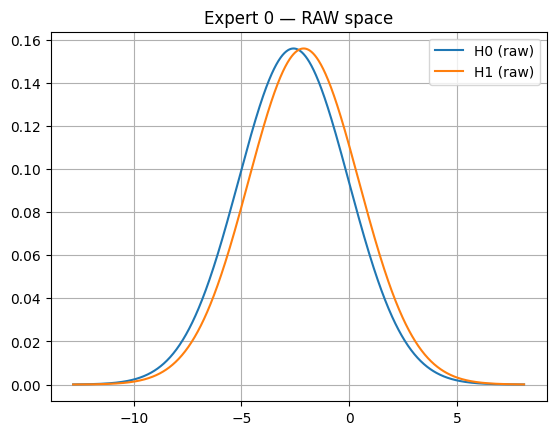

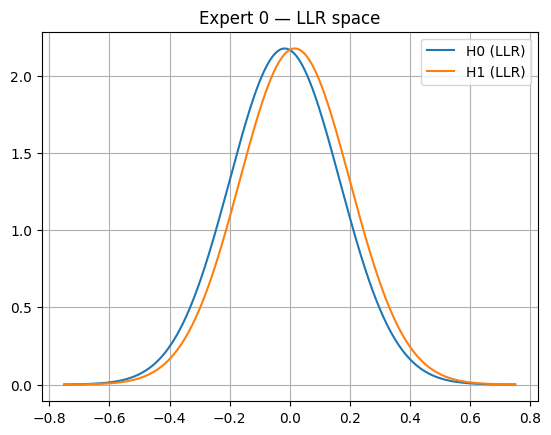

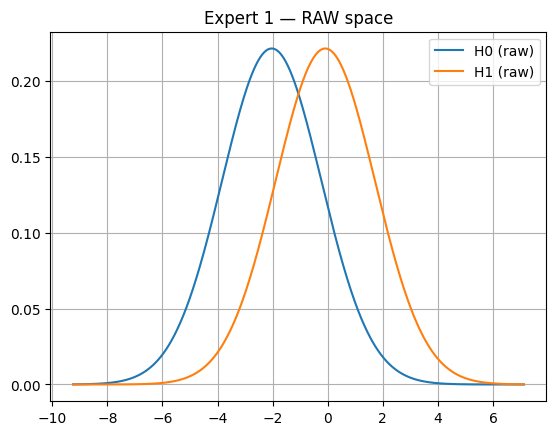

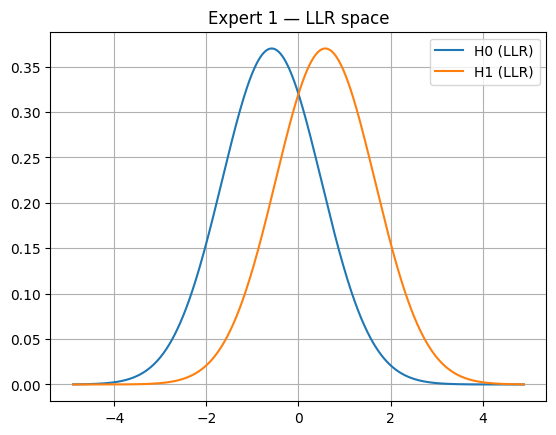

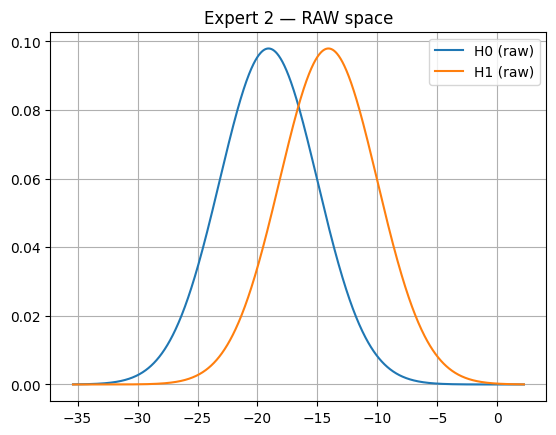

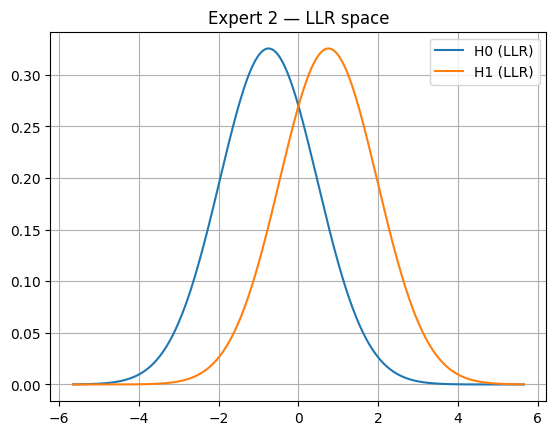

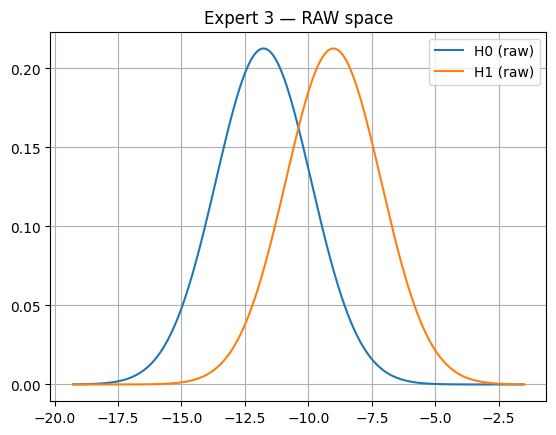

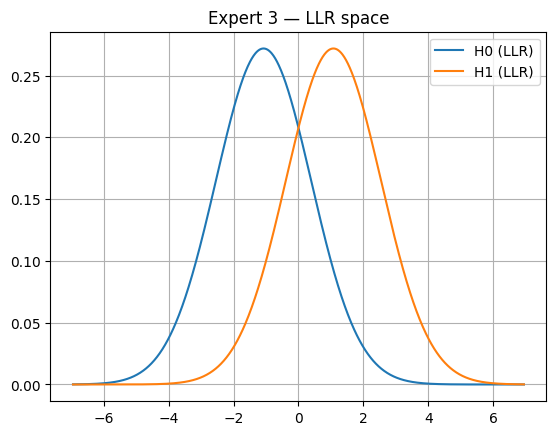

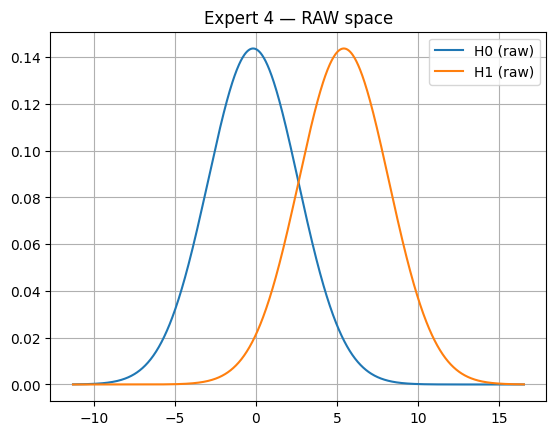

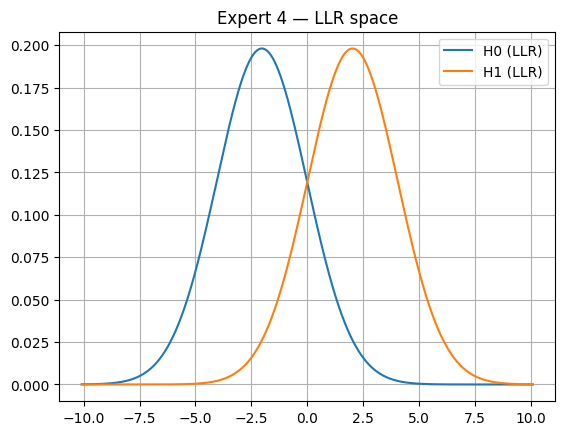

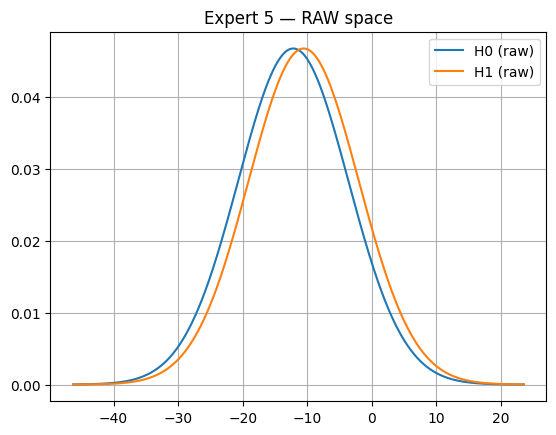

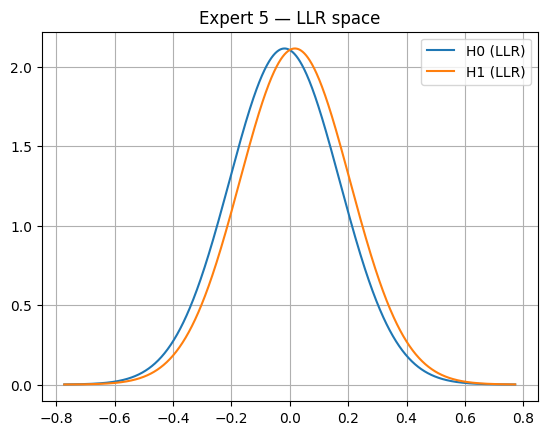

In [42]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_asv19/temp/trials10"
all_me = np.load(f"{rootpath}/all_me.npy")
all_md = np.load(f"{rootpath}/all_md.npy")
all_v = np.load(f"{rootpath}/all_v.npy")

plot_distributions(all_me, all_md, all_v)